# Molecular Feature Selection Framework — BUG-FIXED, Colab-ready

Fixes applied vs. the original notebook:
1. **Stage 7 (SHAP final eval) NameError fixed** — `X_train2/y_train2/X_test2/y_test2` were undefined. Replaced with a proper split of `X_shap, y_shap` (the actual SHAP-selected feature set), so the printed 'ROC-AUC using SHAP-selected features' now genuinely uses those features.
2. **Explicit `import lightgbm as lgb`** added at the top instead of relying on it leaking into global scope from inside a try/except in a loop (fragile in Colab if cells are re-run out of order).
3. **Install cell rewritten for Colab** (conda isn't available there) — switched to `pip install`.
4. **Removed unused `dcor` install** — it was never imported/used anywhere downstream.
5. Split the original single giant cell into one cell per stage so you can run/debug incrementally and inspect intermediate shapes.

In [1]:
# Colab-friendly install (run once)
!pip install rdkit lightgbm shap tqdm --quiet


In [2]:
# Setup, reproducibility
import numpy as np, pandas as pd, random, os
from rdkit import rdBase, Chem
from rdkit.Chem import DataStructs, Draw, rdFingerprintGenerator
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb  # FIX: explicit top-level import, not relying on loop-scope leakage
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'

print('RDKit version:', rdBase.rdkitVersion)
print('Reproducibility seed set to', SEED)


RDKit version: 2026.03.3
Reproducibility seed set to 42


In [3]:
#   1. Loading and cleaning dataset
data = pd.read_csv('molecule_classification_dataset.csv')
df = data.copy()
print('Initial shape:', df.shape)

if 'Name' in df.columns:
    df = df.drop('Name', axis=1)

df.columns = df.columns.str.strip()

if 'ChEMBL ID' in df.columns:
    df['ChEMBL ID'] = df['ChEMBL ID'].astype(str).str.replace('CHEMBL', '', regex=False)

for col in ['LogP', 'HBA', 'HBD', 'TPSA']:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].mean())

if 'Protein' in df.columns:
    df['BACE1_activity'] = (df['Protein'] == 'BACE1').astype(int)
else:
    raise KeyError("Column 'Protein' not found.")

print('Class balance:', df['BACE1_activity'].value_counts(normalize=True).to_dict())


Initial shape: (8711, 10)
Class balance: {1: 0.8565032717254046, 0: 0.14349672827459534}


In [4]:
#   2. Morgan fingerprints
def smiles_to_morgan_fp(smiles, radius=2, n_bits=1024):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=n_bits)
    fp = morgan_gen.GetFingerprint(mol)
    arr = np.zeros((n_bits,), dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

fps, valid_idx = [], []
for idx, smi in df['SMILES'].astype(str).items():
    arr = smiles_to_morgan_fp(smi)
    if arr is None:
        continue
    fps.append(arr)
    valid_idx.append(idx)

print(f'Parsed {len(fps)} valid molecules | Dropped {len(df) - len(fps)} invalid SMILES')
if len(fps) == 0:
    raise SystemExit('No valid SMILES parsed.')

possible_desc = ['Molecular Weight','MolecularWeight','MolWeight','LogP','HBA','HBD','TPSA','BACE1_activity']
desc_cols = [c for c in possible_desc if c in df.columns]
meta_cols = [c for c in ['ChEMBL ID','SMILES'] if c in df.columns]

fp_array = np.vstack(fps)
fp_cols = [f'fp_{i}' for i in range(fp_array.shape[1])]
df_fp = pd.DataFrame(fp_array, columns=fp_cols).reset_index(drop=True)
df_desc = df.loc[valid_idx, desc_cols].reset_index(drop=True)
df_meta = df.loc[valid_idx, meta_cols].reset_index(drop=True)

df_features = pd.concat([df_meta, df_desc, df_fp], axis=1)
print('Final feature matrix shape:', df_features.shape)


Parsed 8711 valid molecules | Dropped 0 invalid SMILES
Final feature matrix shape: (8711, 1032)


In [5]:
#   3. Correlation pruning
feature_cols = df_features.drop(columns=meta_cols)
corr_matrix = feature_cols.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if any(upper[c] > 0.9)]
df_reduced = feature_cols.drop(columns=to_drop)
print(f'Dropped {len(to_drop)} redundant features (>0.9 corr). Remaining:', df_reduced.shape[1])


Dropped 0 redundant features (>0.9 corr). Remaining: 1030


In [6]:
#   4. Leakage-free CV feature selection (Steps 2+3)
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

X = df_reduced.drop(columns=['BACE1_activity'])
y = df_reduced['BACE1_activity']

n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)

var_threshold = 0.01
mi_threshold = 0.01
top_pct = 0.50
min_keep = 500

selected_feature_sets = []
print(f'Performing {n_splits}-fold leakage-free feature selection...')

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]

    variances = X_train.var()
    mi_scores = mutual_info_classif(X_train, y_train, discrete_features='auto', random_state=SEED)
    mi_df = pd.DataFrame({'Feature': X.columns, 'Variance': variances.values, 'MI': mi_scores})
    mask = (mi_df['Variance'] > var_threshold) | (mi_df['MI'] > mi_threshold)
    X_filtered = X_train[mi_df.loc[mask, 'Feature']]
    print(f'Fold {fold}: after variance/MI filter: {X_filtered.shape[1]} features')

    model = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=64,
                                n_jobs=-1, random_state=SEED, verbosity=-1)
    model.fit(X_filtered, y_train)
    importances = pd.Series(model.feature_importances_, index=X_filtered.columns).sort_values(ascending=False)

    top_k = max(min_keep, int(np.ceil(top_pct * len(importances))))
    top_k = min(top_k, len(importances))
    top_features_fold = importances.head(top_k).index.tolist()
    print(f'Fold {fold}: selected {len(top_features_fold)} top features')
    selected_feature_sets.append(top_features_fold)

from collections import Counter
all_features = [feat for sublist in selected_feature_sets for feat in sublist]
feature_counts = Counter(all_features)
stable_features = [feat for feat, count in feature_counts.items() if count >= 3]
print(f'Stable features across folds: {len(stable_features)}')

df_reduced_final = df_reduced[stable_features + ['BACE1_activity']]
print('df_reduced_final shape:', df_reduced_final.shape)


Performing 5-fold leakage-free feature selection...
Fold 1: after variance/MI filter: 821 features
Fold 1: selected 500 top features
Fold 2: after variance/MI filter: 828 features
Fold 2: selected 500 top features
Fold 3: after variance/MI filter: 827 features
Fold 3: selected 500 top features
Fold 4: after variance/MI filter: 834 features
Fold 4: selected 500 top features
Fold 5: after variance/MI filter: 832 features
Fold 5: selected 500 top features
Stable features across folds: 495
df_reduced_final shape: (8711, 496)


In [7]:
#   5. LASSO shrinkage
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import roc_auc_score

X = df_reduced_final.drop(columns=['BACE1_activity'])
y = df_reduced_final['BACE1_activity']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

lasso = LogisticRegressionCV(
    Cs=10, penalty='l1', solver='saga', scoring='roc_auc',
    cv=5, max_iter=5000, n_jobs=-1, random_state=SEED, refit=True
)
lasso.fit(X_train_scaled, y_train)
coef = np.abs(lasso.coef_).ravel()
selected = X.columns[coef > 1e-6].tolist()

y_pred_proba = lasso.predict_proba(X_val_scaled)[:, 1]
auc = roc_auc_score(y_val, y_pred_proba)
print(f'LASSO validation ROC-AUC: {auc:.4f}')

df_lasso_final = pd.concat([X[selected].reset_index(drop=True), y.reset_index(drop=True)], axis=1)
print(f'Final LASSO-selected features: {len(selected)} | Dropped: {len(X.columns) - len(selected)}')


LASSO validation ROC-AUC: 0.9940
Final LASSO-selected features: 313 | Dropped: 182


In [8]:
#   6. SHAP interpretability & refinement
import shap
from lightgbm import LGBMClassifier

df = df_lasso_final.copy() if 'df_lasso_final' in globals() else df_reduced_final.copy()
X = df.drop(columns=['BACE1_activity'])
y = df['BACE1_activity']
print(f'Data for SHAP: {X.shape[0]} samples x {X.shape[1]} features')

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = LGBMClassifier(
    n_estimators=500, learning_rate=0.05, num_leaves=64,
    subsample=0.8, colsample_bytree=0.8,
    random_state=SEED, n_jobs=-1, verbosity=-1
)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print(f'Validation ROC-AUC before SHAP refinement: {auc:.4f}')

explainer = shap.TreeExplainer(model)
sample_idx = np.random.choice(X_train.shape[0], size=min(1000, X_train.shape[0]), replace=False)
X_sample = X_train.iloc[sample_idx]
shap_values_raw = explainer.shap_values(X_sample)

if isinstance(shap_values_raw, list):
    shap_values = shap_values_raw[1] if len(shap_values_raw) > 1 else shap_values_raw[0]
else:
    shap_values = shap_values_raw

shap_importance = pd.DataFrame({
    'Feature': X.columns,
    'MeanAbsSHAP': np.abs(shap_values).mean(axis=0)
}).sort_values(by='MeanAbsSHAP', ascending=False).reset_index(drop=True)

top_k = 150
selected_features = shap_importance.head(top_k)['Feature'].tolist()

df_shap_final = pd.concat([
    df[selected_features].reset_index(drop=True),
    df['BACE1_activity'].reset_index(drop=True)
], axis=1)

print(f'Kept after SHAP ranking: {len(selected_features)}')
shap_importance.to_csv('shap_importance_after_lasso.csv', index=False)
df_shap_final.to_csv('df_shap_final.csv', index=False)


Data for SHAP: 8711 samples x 313 features
Validation ROC-AUC before SHAP refinement: 0.9977
Kept after SHAP ranking: 150


In [ ]:
#   6b. FIXED final eval using SHAP-selected features
# ORIGINAL BUG: referenced undefined X_train2/y_train2/X_test2/y_test2.
# FIX: split X_shap, y_shap (the actual SHAP-trimmed feature set) properly.
X_shap = df_shap_final.drop(columns=['BACE1_activity'])
y_shap = df_shap_final['BACE1_activity']

X_train_shap, X_val_shap, y_train_shap, y_val_shap = train_test_split(
    X_shap, y_shap, test_size=0.2, stratify=y_shap, random_state=42
)

model_shap = LGBMClassifier(
    n_estimators=500, learning_rate=0.05, num_leaves=64, random_state=SEED, verbosity=-1
)
model_shap.fit(X_train_shap, y_train_shap)
y_pred2 = model_shap.predict_proba(X_val_shap)[:, 1]
auc_shap = roc_auc_score(y_val_shap, y_pred2)
print(f'Final validation ROC-AUC using SHAP-selected features: {auc_shap:.4f}')

if 'df_meta' in globals() and 'SMILES' in df_meta.columns:
    df_shap_final = pd.concat([
        df_meta[['SMILES']].reset_index(drop=True),
        df[selected_features].reset_index(drop=True),
        df['BACE1_activity'].reset_index(drop=True)
    ], axis=1)
    print('Appended SMILES column for interpretability.')


In [10]:
#   7. Scaffold split evaluation
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.metrics import precision_recall_curve, auc

def scaffold_split(df, smiles_col='SMILES', test_frac=0.2, seed=SEED):
    scaffolds = {}
    for i, smi in enumerate(df[smiles_col]):
        mol = Chem.MolFromSmiles(smi)
        if mol:
            scaf = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
            scaffolds.setdefault(scaf, []).append(i)
    scaffold_sets = sorted(scaffolds.values(), key=lambda x: len(x), reverse=True)
    train_idx, test_idx = [], []
    total = len(df)
    for s in scaffold_sets:
        if len(test_idx) + len(s) < test_frac * total:
            test_idx.extend(s)
        else:
            train_idx.extend(s)
    return train_idx, test_idx

train_idx, test_idx = scaffold_split(df_shap_final)
train_df, test_df = df_shap_final.iloc[train_idx], df_shap_final.iloc[test_idx]

X_train, y_train = train_df.drop(columns=['SMILES', 'BACE1_activity']), train_df['BACE1_activity']
X_test, y_test = test_df.drop(columns=['SMILES', 'BACE1_activity']), test_df['BACE1_activity']

model_scaffold = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=64, random_state=SEED, verbosity=-1)
model_scaffold.fit(X_train, y_train)
y_pred = model_scaffold.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred)
prec, rec, _ = precision_recall_curve(y_test, y_pred)
pr_auc = auc(rec, prec)
print(f'Scaffold-split ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f}')


Scaffold-split ROC-AUC: 0.9988 | PR-AUC: 0.9998


In [11]:
#   8. Bootstrap stability selection
from tqdm import tqdm

X_data = df_shap_final.drop(columns=['SMILES', 'BACE1_activity'])
y_data = df_shap_final['BACE1_activity']
n_bootstrap = 50
bootstrap_top_k = int(0.4 * X_data.shape[1])
selected_counts = Counter()

for i in tqdm(range(n_bootstrap), desc='Bootstrap runs'):
    idx = np.random.choice(len(X_data), len(X_data), replace=True)
    Xb, yb = X_data.iloc[idx], y_data.iloc[idx]
    model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=64, random_state=SEED + i, verbosity=-1)
    model.fit(Xb, yb)
    imps = pd.Series(model.feature_importances_, index=X_data.columns)
    top_feats = imps.sort_values(ascending=False).head(bootstrap_top_k).index.tolist()
    selected_counts.update(top_feats)

freq_df = pd.DataFrame({'Feature': list(selected_counts.keys()),
                        'Count': [selected_counts[f] for f in selected_counts.keys()]})
freq_df['Frequency'] = freq_df['Count'] / n_bootstrap
freq_df = freq_df.sort_values('Frequency', ascending=False)
freq_df.to_csv('feature_stability_frequency.csv', index=False)

freq_threshold = 0.25
robust_features = freq_df[freq_df['Frequency'] >= freq_threshold]['Feature'].tolist()
print(f'Stability selection complete. Robust features (>= {freq_threshold}): {len(robust_features)}')


Bootstrap runs: 100%|██████████| 50/50 [00:56<00:00,  1.12s/it]

Stability selection complete. Robust features (>= 0.25): 73


Evaluating stability selection quality...


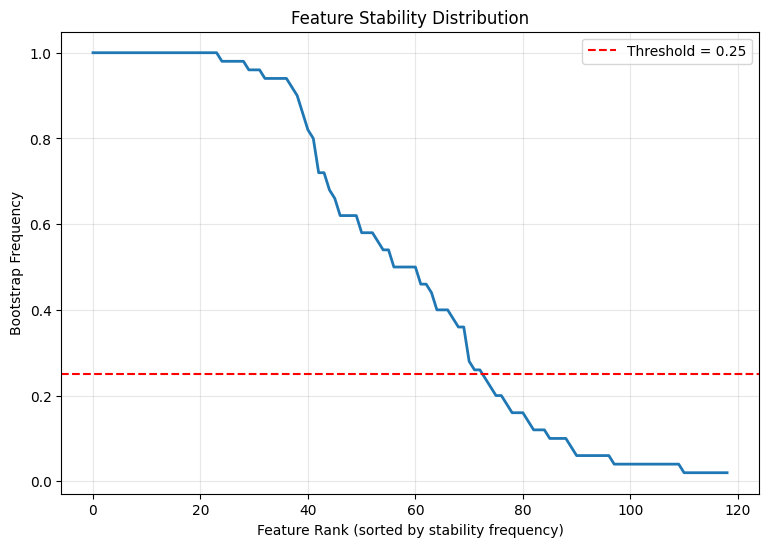

STABILITY SELECTION EVALUATION SUMMARY
Total SHAP features tested       : 150
Stable features retained (>=0.25) : 73
Model AUC (All SHAP features)    : 0.9978
Model AUC (Stable-only features) : 0.9980
Delta AUC (drop in performance)  : -0.0002
PR-AUC (Full / Stable)           : 0.9996 / 0.9996
Correlation (Stability vs SHAP)  : 0.435
Acceptable: performance can be tweaked by threshold variability


In [12]:
#   9. Stability selection evaluation report
print('Evaluating stability selection quality...')

X_full = X_data[selected_features].copy()
X_stable = X_data[robust_features].copy()
y = y_data.copy()

X_train, X_test, y_train, y_test = train_test_split(X_full, y, test_size=0.2, stratify=y, random_state=42)

model_full = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=64, random_state=42, verbosity=-1)
model_full.fit(X_train, y_train)
y_pred_full = model_full.predict_proba(X_test)[:, 1]
auc_full = roc_auc_score(y_test, y_pred_full)
prec_full, rec_full, _ = precision_recall_curve(y_test, y_pred_full)
pr_auc_full = auc(rec_full, prec_full)

X_train_s, X_test_s = X_train[robust_features], X_test[robust_features]
model_stable = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=64, random_state=42, verbosity=-1)
model_stable.fit(X_train_s, y_train)
y_pred_stable = model_stable.predict_proba(X_test_s)[:, 1]
auc_stable = roc_auc_score(y_test, y_pred_stable)
prec_stable, rec_stable, _ = precision_recall_curve(y_test, y_pred_stable)
pr_auc_stable = auc(rec_stable, prec_stable)

merged = freq_df.merge(shap_importance, on='Feature', how='left')
stability_shap_corr = merged['Frequency'].corr(merged['MeanAbsSHAP'])

plt.figure(figsize=(9,6))
plt.plot(range(len(freq_df)), sorted(freq_df['Frequency'], reverse=True), lw=2)
plt.axhline(y=freq_threshold, color='r', linestyle='--', label=f'Threshold = {freq_threshold}')
plt.xlabel('Feature Rank (sorted by stability frequency)')
plt.ylabel('Bootstrap Frequency')
plt.title('Feature Stability Distribution')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print('='*65)
print('STABILITY SELECTION EVALUATION SUMMARY')
print('='*65)
print(f'Total SHAP features tested       : {len(selected_features)}')
print(f'Stable features retained (>={freq_threshold}) : {len(robust_features)}')
print(f'Model AUC (All SHAP features)    : {auc_full:.4f}')
print(f'Model AUC (Stable-only features) : {auc_stable:.4f}')
print(f'Delta AUC (drop in performance)  : {auc_full - auc_stable:.4f}')
print(f'PR-AUC (Full / Stable)           : {pr_auc_full:.4f} / {pr_auc_stable:.4f}')
print(f'Correlation (Stability vs SHAP)  : {stability_shap_corr:.3f}')
print('='*65)

if (auc_full - auc_stable) < 0.02 and stability_shap_corr > 0.5:
    print('Excellent: Stability-selected features retain performance and align with SHAP importance.')
elif (auc_full - auc_stable) < 0.05:
    print('Acceptable: performance can be tweaked by threshold variability')
else:
    print('Noticeable performance drop - stability selection may be too aggressive.')


In [ ]:
#   10. Enrichment Factor — virtual screening metric
# EF@X% answers: if we only screened the top X% of molecules ranked by the
# model, how many more true actives would we find vs. picking randomly?
# EF = (hit rate in top X%) / (baseline hit rate in full set)

def enrichment_factor(y_true, y_scores, top_fraction):
    y_true = np.asarray(y_true)
    y_scores = np.asarray(y_scores)
    n_total = len(y_true)
    n_top = max(1, int(np.ceil(top_fraction * n_total)))

    order = np.argsort(y_scores)[::-1]   # descending by predicted score
    top_idx = order[:n_top]

    hits_in_top = y_true[top_idx].sum()
    hit_rate_top = hits_in_top / n_top
    baseline_rate = y_true.sum() / n_total
    ef = hit_rate_top / baseline_rate if baseline_rate > 0 else np.nan
    return ef, hit_rate_top, baseline_rate

fractions = [0.01, 0.05, 0.10, 0.20]
y_test_arr = y_test.values if hasattr(y_test, 'values') else np.asarray(y_test)

print('=' * 70)
print('ENRICHMENT FACTOR  |  Stability-Selected Model (73 features)')
print('=' * 70)
ef_rows = []
for frac in fractions:
    ef, hit_rate, baseline = enrichment_factor(y_test_arr, y_pred_stable, frac)
    ef_rows.append({'Top %': f'{frac*100:.0f}%', 'Model': 'Stable (73 feat)',
                     'Hit Rate': hit_rate, 'Baseline Rate': baseline, 'EF': ef})
    print(f'Top {frac*100:>5.1f}%  |  Hit Rate: {hit_rate:.4f}  |  '
          f'Baseline: {baseline:.4f}  |  EF: {ef:.2f}x')

print()
print('=' * 70)
print('ENRICHMENT FACTOR  |  Full SHAP Feature Model (150 features)')
print('=' * 70)
for frac in fractions:
    ef, hit_rate, baseline = enrichment_factor(y_test_arr, y_pred_full, frac)
    ef_rows.append({'Top %': f'{frac*100:.0f}%', 'Model': 'Full (150 feat)',
                     'Hit Rate': hit_rate, 'Baseline Rate': baseline, 'EF': ef})
    print(f'Top {frac*100:>5.1f}%  |  Hit Rate: {hit_rate:.4f}  |  '
          f'Baseline: {baseline:.4f}  |  EF: {ef:.2f}x')

ef_df = pd.DataFrame(ef_rows)
ef_df.to_csv('enrichment_factor_results.csv', index=False)

# Plot: EF curve comparing stable vs full feature model
plt.figure(figsize=(8, 5))
for model_label, marker in [('Stable (73 feat)', 'o'), ('Full (150 feat)', 's')]:
    sub = ef_df[ef_df['Model'] == model_label]
    plt.plot([float(p.strip('%')) for p in sub['Top %']], sub['EF'],
              marker=marker, label=model_label, linewidth=2)
plt.axhline(y=1.0, color='gray', linestyle='--', label='Random baseline (EF=1)')
plt.xlabel('Top % of Ranked Molecules Screened')
plt.ylabel('Enrichment Factor')
plt.title('Enrichment Factor: Stable vs. Full Feature Set')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# IMPORTANT INTERPRETATION NOTE:
# This dataset's positive class (BACE1) makes up ~85.6% of all molecules,
# so the theoretical maximum EF here is only ~1/0.856 = 1.17x. Enrichment
# Factor is designed for the classic virtual-screening scenario where true
# actives are RARE (e.g., 1-5% of a compound library) and you're trying to
# find a needle in a haystack. With positives as the majority class, EF is
# not very informative here -- this is worth stating explicitly if asked
# about it, rather than presenting a 1.0-1.1x EF as if it were a strong result.
print()
print('NOTE: Baseline positive rate is high (~85.6%), so EF has a low ceiling')
print('(~1.17x max) here. EF is most meaningful when actives are rare.')
